# Data Science Society Workshop 04 - Build your first ML model

**Intro to Machine Learning Week 1**

A notebook is made of **cells**. Text cells explain; code cells run Python code.

Click a code cell and press **Shift + Enter** to run it.

If something breaks: **Runtime → Run all**. Run cells **top to bottom**.

> Before we get started: **File → Save a copy in Drive**, so your changes are saved.

#  Warm-up

## Your first code

In [ ]:
print("Hello, DSS!")   # print shows text on the screen

Hello, DSS!


In [ ]:
2 + 2   # Python works like a calculator

4

In [ ]:
price = 925000   # a variable is a labelled box that stores a value
price * 2

1850000

## Load the table, plot it

In [ ]:
import pandas as pd
import warnings

DATA_URL = "https://raw.githubusercontent.com/Shafyyah/ucldss-ml-workshop/main/data/flats.csv"

df = pd.read_csv(DATA_URL)
print(f"Loaded dataset: {DATA_URL.split('/')[-1]}")

Loaded dataset: flats.csv


In [ ]:
df.head()   # the first 5 rows: one row = one flat

,size_m2,price_k,bedrooms,area,type
0,109,2275.0,3,Primrose Hill,New development
1,109,800.0,3,West Hampstead,Flat / Apartment
2,43,500.0,1,Kentish Town,Flat / Apartment
3,81,752.5,2,Belsize Park,New development
4,66,995.0,2,Primrose Hill,Flat / Apartment


In [ ]:
len(df)   # how many flats?

94

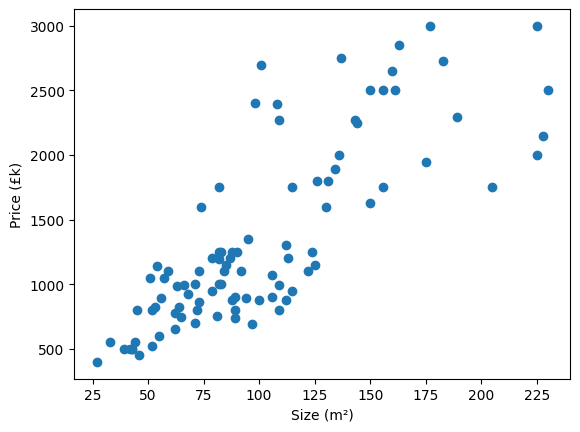

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(df["size_m2"], df["price_k"])
plt.xlabel("Size (m²)")
plt.ylabel("Price (£k)")
plt.show()

# 1. Build a model to predict prices
 Replace each `___` with your own code.

## Split into training and test sets
Training flats = practice questions. Test flats = the exam, set aside until the end.

In [ ]:
from sklearn.model_selection import train_test_split

X = df[["size_m2"]]   # input
y = df["price_k"]     # answer

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(len(X_train), "flats for training,", len(X_test), "flats for testing")

75 flats for training, 19 flats for testing


## Fit the line
Fill in the blanks: the model learns from the **training** flats.

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(___, ___)
model.coef_, model.intercept_

ValueError: Expected 2D array, got scalar array instead:
array=1850000.
Reshape your data either using array.reshape(-1, 1) if your data has a single feature or array.reshape(1, -1) if it contains a single sample.

## The best fit line
**price = m × size + c**

In [ ]:
m = model.coef_[0]
c = model.intercept_
print(f"price = {m:.2f} × size + {c:.0f}")
print(f"m: about £{m*1000:,.0f} per extra m²")
print(f"c: a starting value of about £{c:,.0f}k")

In [ ]:
sizes = pd.DataFrame({"size_m2": range(int(X["size_m2"].min()), int(X["size_m2"].max()) + 1)})

plt.scatter(X_train["size_m2"], y_train, alpha=0.6, label="training flats")
plt.plot(sizes["size_m2"], model.predict(sizes), color="red", linewidth=2, label="the best line")
plt.xlabel("Size (m²)")
plt.ylabel("Asking price (£k)")
plt.legend()
plt.show()

## Predict like the model
Flat 1 from the game: **68 m²**. By hand:

In [ ]:
m * 68 + c   # → about 930

In code. Then try your own size!

In [ ]:
model.predict([[68]])   # → about 930

my_flat = ___   # your own size!
model.predict([[my_flat]])

## Testing on unseen flats
For each test flat: how far off was the model's guess?
We average those gaps, then compare with a lazy guess that always says the average price.

In [ ]:
from sklearn.metrics import mean_absolute_error

average_price = y_train.mean()
lazy_miss = mean_absolute_error(y_test, [average_price] * len(y_test))
line_miss = mean_absolute_error(y_test, model.predict(X_test))

print(f"Always guess £{average_price:,.0f}k: misses by £{lazy_miss:,.0f}k")
print(f"Our line: misses by £{line_miss:,.0f}k")

## Why it still misses
It only knows size. The big dot is the biggest miss.

In [ ]:
test = df.loc[X_test.index].copy()
test["model_k"] = model.predict(X_test)
test["missed_by_k"] = (test["model_k"] - test["price_k"]).abs()
worst = test.sort_values("missed_by_k").iloc[-1]

plt.scatter(test["size_m2"], test["price_k"], alpha=0.6, label="test flats")
plt.plot(sizes["size_m2"], model.predict(sizes), color="red", linewidth=2, label="our line")
plt.scatter([worst["size_m2"]], [worst["price_k"]], s=200, color="red", edgecolor="black", label="biggest miss")
plt.xlabel("Size (m²)")
plt.ylabel("Asking price (£k)")
plt.legend()
plt.show()

print(f"Biggest miss: a {worst['size_m2']:.0f} m² flat in {worst.get('area', '?')}, "
      f"real £{worst['price_k']:,.0f}k vs model £{worst['model_k']:,.0f}k "
      f"(missed by £{worst['missed_by_k']:,.0f}k)")

## Replay the game
Run the cell, then play against the person next to you.

In [ ]:
# Replay the game: you vs your model
flats = df.loc[X_test.index].sample(4)
flats["model_k"] = model.predict(flats[["size_m2"]])
you, bot = 0, 0

for _, flat in flats.iterrows():
    print(f"\n {flat['size_m2']} m², {flat['bedrooms']} bed, {flat['area']}")
    guess = float(input("Your guess (£k): "))
    print(f"Model: £{flat['model_k']:.0f}k | Real: £{flat['price_k']:.0f}k")

    if abs(guess - flat["price_k"]) < abs(flat["model_k"] - flat["price_k"]):
        you += 1
        print("You win this one! ")
    else:
        bot += 1
        print("The model wins this one ")

print(f"\nFinal score: You {you} – {bot} Model")

## What you did today
1. **Split**: flats for training, flats set aside for testing
2. **Fit**: a line, price = m × size + c
3. **Test**: how far off it is on flats it has never seen

**Next week:** how did the computer find the line?

# Sneak peek: watch a model learn

Today, `model.fit()` found the best line instantly. But how? Run the cell below and move the sliders to watch the line find its own way there, one step at a time:

1. **Guess** a price for every training flat
2. **Check** how far off each guess is
3. **Adjust** the line a little to shrink the miss
4. **Repeat**

Try these:
- Slide **steps** from 0 up to 300. Where does the line end up? Compare it to scikit-learn's answer.
- Set **step size** to 0.01. Why is it so slow?
- Set **step size** to 0.5. What happens?

**Where this is going**
- **Next week (Week 2):** we open the box. You'll see why this guess–check–adjust loop works, write it yourself and train it with PyTorch.
- **Week 3:** we swap the straight line for a neural network and teach it to read your handwriting. Same loop, just millions of tiny adjustments.

In [42]:
# Next week's sneak peek: watch a model LEARN the line, one step at a time
# Just run this cell, then move the sliders. No need to read the code (yet!)
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, SelectionSlider

x = X_train["size_m2"].values / 100   # sizes in hundreds of m² (keeps the numbers small)
y = y_train.values                     # prices in £k

def learn(steps, step_size):
    m, c = 0.0, 0.0                    # start with a flat line at £0
    history, errors = [(m, c)], []
    for _ in range(steps):
        guess = m * x + c              # 1. GUESS a price for every training flat
        miss = guess - y               # 2. CHECK how far off each guess is
        errors.append(np.mean(np.abs(miss)))
        m -= step_size * 2 * np.mean(miss * x)   # 3. ADJUST m and c a little,
        c -= step_size * 2 * np.mean(miss)       #    in the direction that shrinks the miss
        history.append((m, c))
        if not np.isfinite(m) or abs(m) > 1e6:   # it's exploding, stop here
            break

    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.5))
    sizes = np.linspace(0, 2.4, 50)
    for mm, cc in history[:: max(1, len(history) // 12)]:
        left.plot(sizes * 100, mm * sizes + cc, color="grey", alpha=0.25)   # earlier attempts
    left.scatter(x * 100, y, alpha=0.6, label="training flats")
    left.plot(sizes * 100, m * sizes + c, color="red", linewidth=3, label=f"after {len(history)-1} steps")
    left.set_ylim(0, 3200); left.set_xlim(0, 240)
    left.set_xlabel("Size (m²)"); left.set_ylabel("Asking price (£k)"); left.legend(loc="upper left")

    right.plot(errors, color="red")
    right.set_xlim(0, max(steps, 1)); right.set_ylim(0, 1500)
    right.set_xlabel("Step"); right.set_ylabel("Average miss (£k)")
    right.set_title("Is it getting better?")
    plt.show()

    exploded = len(errors) > 1 and errors[-1] > errors[0]
    if exploded:
        print(" The steps were too big: it overshot, then overshot even more, and exploded.")
    else:
        print(f"After {len(history)-1} steps:  price = {m/100:.2f} × size + {c:.0f}")
        print(f"scikit-learn's answer:   price = {model.coef_[0]:.2f} × size + {model.intercept_:.0f}")

interact(learn,
         steps=IntSlider(value=0, min=0, max=300, step=5, description="steps", continuous_update=False),
         step_size=SelectionSlider(options=[0.01, 0.03, 0.1, 0.3, 0.5], value=0.1,
                                   description="step size", continuous_update=False));

interactive(children=(IntSlider(value=0, continuous_update=False, description='steps', max=300, step=5), Selec…